<a href="https://colab.research.google.com/github/Abidau/MachineLearning/blob/main/TG6_Regresi_244107020212_NaufalAbidAurizky.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Praktikum1

### Langkah 2 - Import Library

In [1]:
import numpy as np
import pandas as pd

### Langkah 3 - Baca Data

In [2]:
data = pd.read_csv('dataset.csv')

### Langkah 4 - Pemahaman Terhadap Data

In [3]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


### Langkah 5 - Visualisasi Data

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

Import library Matplotlib dan Seaborn untuk visualisasi data

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


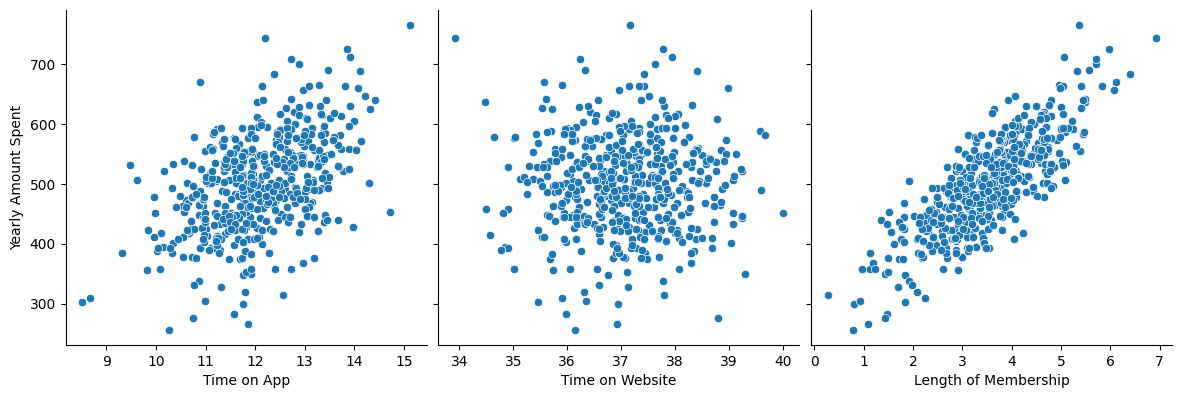

In [6]:
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

Menggunakan pairplot untuk menampilkan hubungan antara variabel bebas dan variabel target dalam bentuk scatter plot

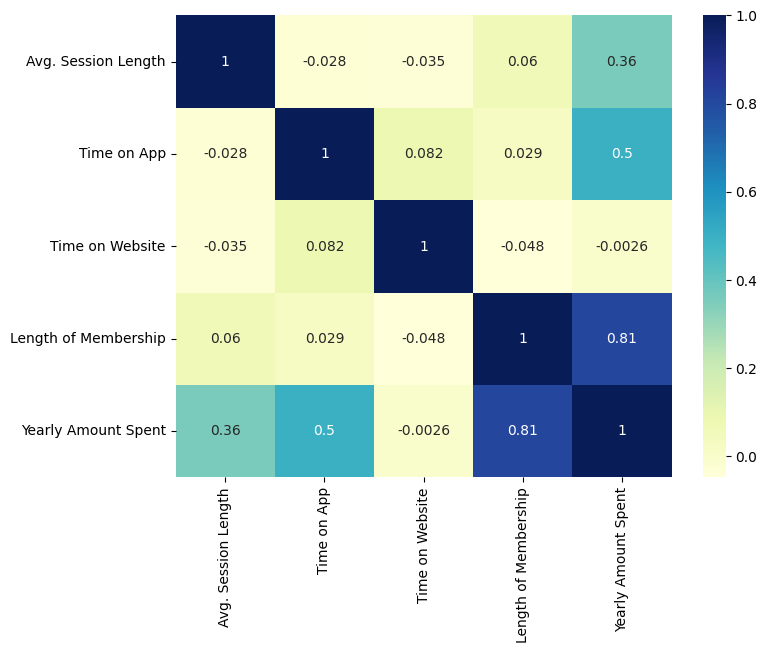

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

### Langkah 6 - Regresi Linier

In [9]:
X = data['Length of Membership']
y = data['Yearly Amount Spent']


Memisahkan variabel bebas (X) dan variabel target (y)

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [11]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

Visualisasikan garis regresi pada data latih

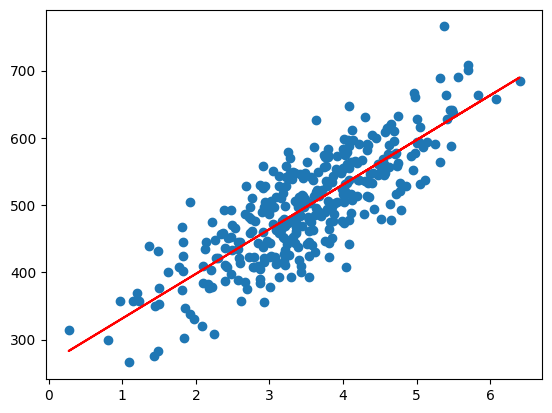

In [12]:
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

### Langkah 7 - Analisis Residual

In [13]:
y_train_pred = lr.predict(X_train_sm)

res = (y_train - y_train_pred)

Melakukan prediksi nilai y dari data latih dan hitung residual (selisih antara nilai sebenarnya dan nilai prediksi)

/tmp/ipykernel_734/530912256.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


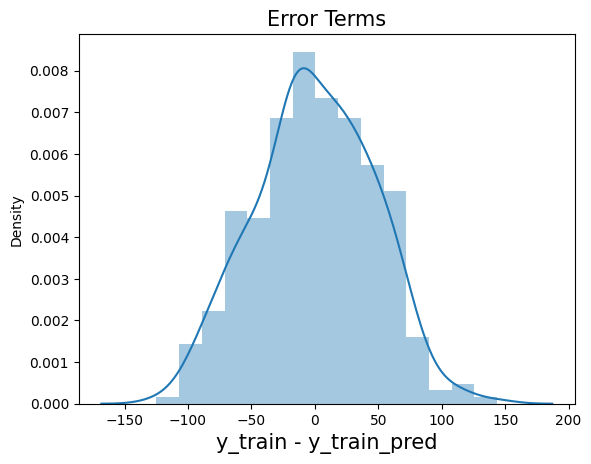

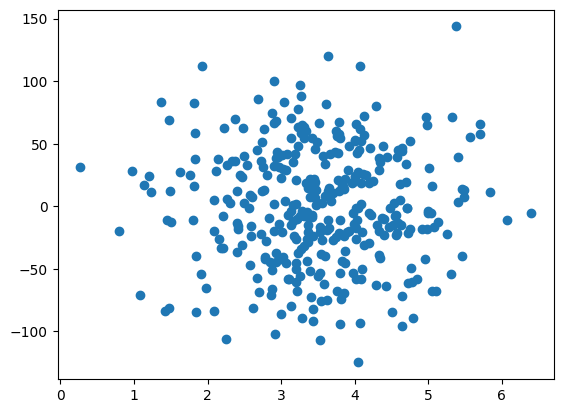

In [14]:
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

plt.scatter(X_train, res)
plt.show()

### Langkah 8 - Prediksi pada Data Uji dan Evaluasi Model

In [16]:
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

Melakukan prediksi pada data uji

In [17]:
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

### Langkah 9 - Visualisasi Hasil

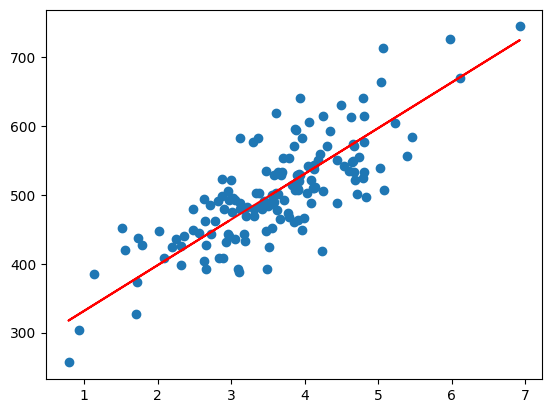

In [19]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

## Praktikum2

### Mengimpor Library

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Mengimpor Dataset

In [22]:
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values

### Feature Scaling

In [23]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

### Fitting SVR ke Dataset

In [24]:
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

### Visualisasi Hasil SVR

/tmp/ipykernel_734/3098558964.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


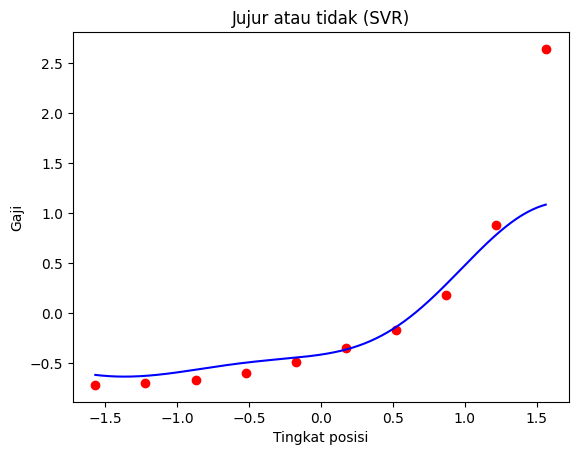

In [25]:
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

### Prediksi Hasil

In [26]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

### Menampilkan Hasil

In [27]:
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


### Evaluasi Model SVR

In [28]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


## Tugas Praktikum

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [30]:
data = pd.read_csv('insurance.csv')
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [31]:
print("Ukuran data:", data.shape)
print("\nJumlah missing value:\n", data.isnull().sum())
print("\nJumlah data duplikat:", data.duplicated().sum())
data.info()

Ukuran data: (1338, 7)

Jumlah missing value:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah data duplikat: 1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### 3. Visualisasi Data (EDA)

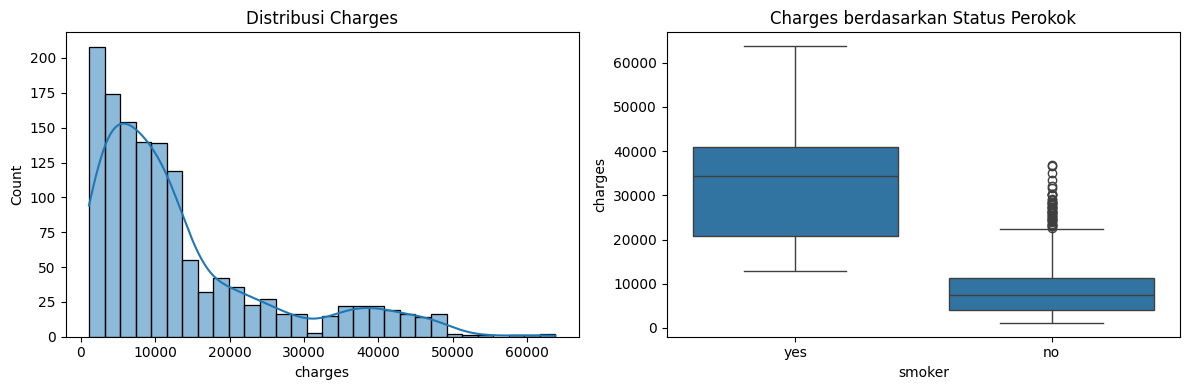

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data['charges'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribusi Charges')
sns.boxplot(x='smoker', y='charges', data=data, ax=axes[1])
axes[1].set_title('Charges berdasarkan Status Perokok')
plt.tight_layout()
plt.show()

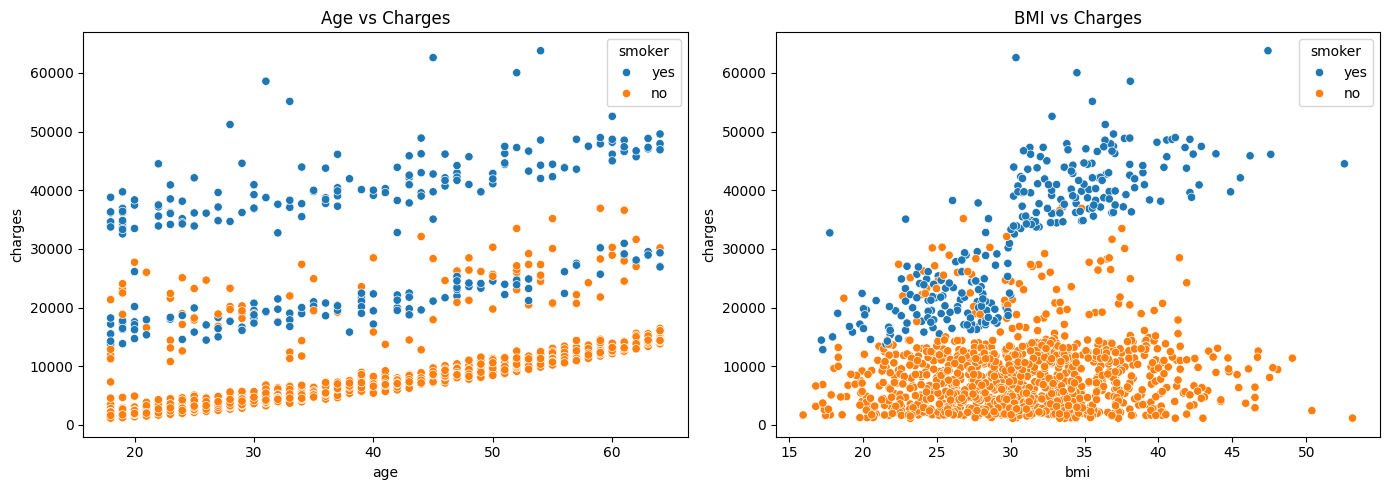

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=data, ax=axes[0])
axes[0].set_title('Age vs Charges')
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=data, ax=axes[1])
axes[1].set_title('BMI vs Charges')
plt.tight_layout()
plt.show()

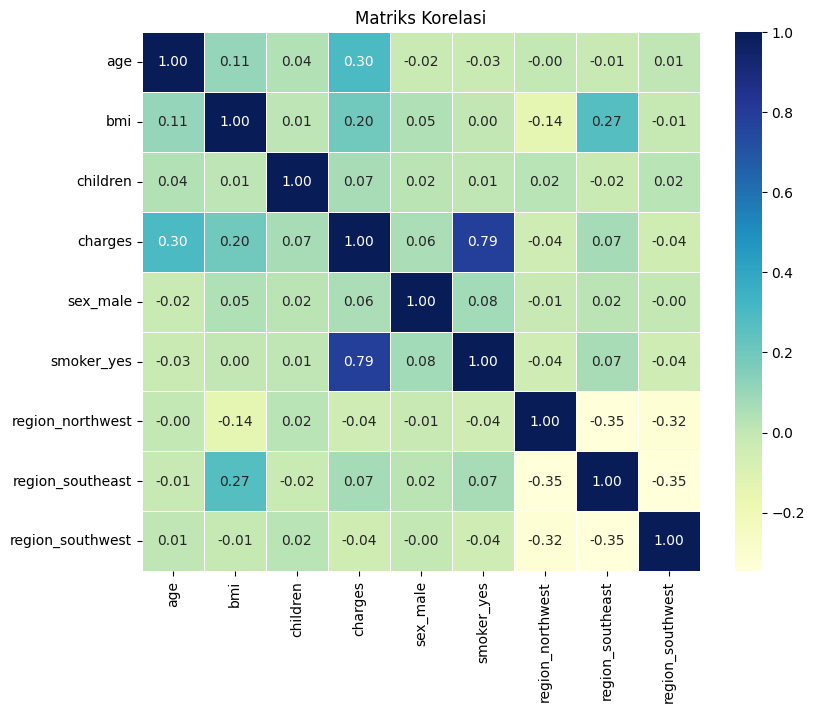

charges             1.000000
smoker_yes          0.787251
age                 0.299008
bmi                 0.198341
region_southeast    0.073982
children            0.067998
sex_male            0.057292
region_northwest   -0.039905
region_southwest   -0.043210
Name: charges, dtype: float64


In [34]:
data_enc = pd.get_dummies(data, drop_first=True).astype(float)
plt.figure(figsize=(9, 7))
sns.heatmap(data_enc.corr(), cmap='YlGnBu', annot=True, fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi')
plt.show()

print(data_enc.corr()['charges'].sort_values(ascending=False))

### 4. Identifikasi Variabel Bebas dan Target

In [35]:
X = data.drop('charges', axis=1)
y = data['charges']

X = pd.get_dummies(X, drop_first=True).astype(float)
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19.0,27.900,0.0,0.0,1.0,0.0,0.0,1.0
1,18.0,33.770,1.0,1.0,0.0,0.0,1.0,0.0
2,28.0,33.000,3.0,1.0,0.0,0.0,1.0,0.0
3,33.0,22.705,0.0,1.0,0.0,1.0,0.0,0.0
4,32.0,28.880,0.0,1.0,0.0,1.0,0.0,0.0


### 5. Pembagian Data Latih dan Data Uji (80:20)

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (1070, 8)
Data uji  : (268, 8)


### 6. Feature Scaling

In [37]:
num_cols = ['age', 'bmi', 'children']

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

X_train_s.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
560,0.472227,-1.756525,0.734336,0.0,0.0,1.0,0.0,0.0
1285,0.543313,-1.033082,-0.911192,0.0,0.0,0.0,0.0,0.0
1142,0.898745,-0.943687,-0.911192,0.0,0.0,0.0,1.0,0.0
969,-0.025379,0.622393,3.202629,0.0,0.0,0.0,1.0,0.0
486,1.040918,-1.504893,1.557100,0.0,0.0,1.0,0.0,0.0


### 7. Membuat dan Melatih Model

In [38]:
model = LinearRegression()
model.fit(X_train_s, y_train)

print("Intercept:", round(model.intercept_, 2))
coef = pd.DataFrame({'Fitur': X_train_s.columns, 'Koefisien': model.coef_})
coef.sort_values('Koefisien', ascending=False)

Intercept: 8955.24


,Fitur,Koefisien
4,smoker_yes,23651.128856
0,age,3614.975415
1,bmi,2036.228123
2,children,516.890247
3,sex_male,-18.591692
5,region_northwest,-370.677326
6,region_southeast,-657.864297
7,region_southwest,-809.799354


### 8. Prediksi pada Data Uji

In [39]:
y_pred = model.predict(X_test_s)
y_train_pred = model.predict(X_train_s)

hasil = pd.DataFrame({'Aktual': y_test.values, 'Prediksi': y_pred.round(2)})
hasil['Selisih'] = hasil['Aktual'] - hasil['Prediksi']
hasil.head(10)

,Aktual,Prediksi,Selisih
0,9095.06825,8969.55,125.51825
1,5272.17580,7068.75,-1796.57420
2,29330.98315,36858.41,-7527.42685
3,9301.89355,9454.68,-152.78645
4,33750.29180,26973.17,6777.12180
5,4536.25900,10864.11,-6327.85100
6,2117.33885,170.28,1947.05885
7,14210.53595,16903.45,-2692.91405
8,3732.62510,1092.43,2640.19510
9,10264.44210,11218.34,-953.89790


### 9. Evaluasi Model

In [40]:
def evaluasi(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {'R-squared': r2_score(y_true, y_hat),
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_hat)}

hasil_eval = pd.DataFrame({'Data Latih': evaluasi(y_train, y_train_pred),
                           'Data Uji': evaluasi(y_test, y_pred)})
hasil_eval.round(4)

,Data Latih,Data Uji
R-squared,7.417000e-01,7.836000e-01
MSE,3.727768e+07,3.359692e+07
RMSE,6.105545e+03,5.796285e+03
MAE,4.208235e+03,4.181194e+03


### 10. Visualisasi Hasil Prediksi

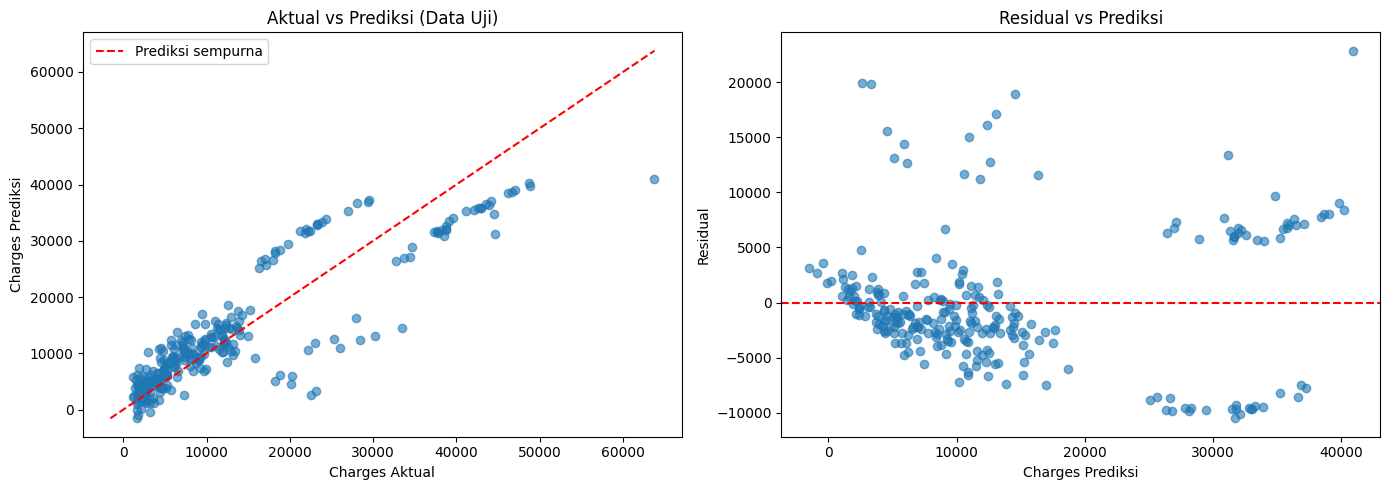

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Aktual vs Prediksi
axes[0].scatter(y_test, y_pred, alpha=0.6)
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lim, lim, 'r--', label='Prediksi sempurna')
axes[0].set_xlabel('Charges Aktual')
axes[0].set_ylabel('Charges Prediksi')
axes[0].set_title('Aktual vs Prediksi (Data Uji)')
axes[0].legend()

# Residual vs Prediksi
res = y_test - y_pred
axes[1].scatter(y_pred, res, alpha=0.6)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Charges Prediksi')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residual vs Prediksi')

plt.tight_layout()
plt.show()

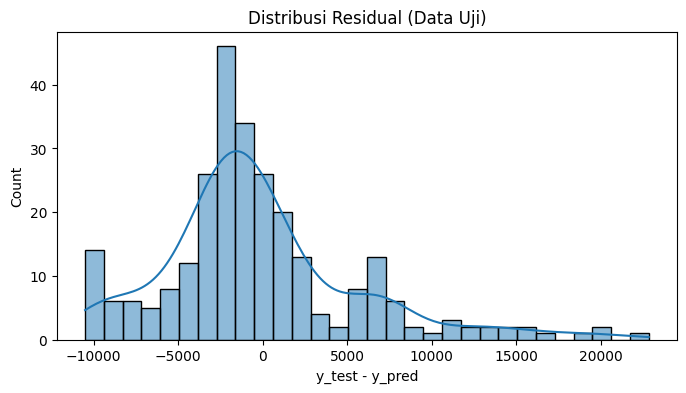

In [42]:
plt.figure(figsize=(8, 4))
sns.histplot(res, bins=30, kde=True)
plt.title('Distribusi Residual (Data Uji)')
plt.xlabel('y_test - y_pred')
plt.show()